In [3]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.utils.class_weight import compute_class_weight

IMG_SIZE = 224
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE

train_df = pd.read_csv("../data/train.csv")
val_df = pd.read_csv("../data/val.csv")
test_df = pd.read_csv("../data/test.csv")

label_map = {"NORMAL": 0, "PNEUMONIA": 1}
for d in (train_df, val_df, test_df):
    d["y"] = d["label"].map(label_map)

In [5]:
def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)   # 3 canaux, requis par les modèles pré-entraînés
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return img, label

# Augmentations légères adaptées aux radios (pas de flip vertical)
augment = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(15 / 360),   # environ ±15°
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomTranslation(0.05, 0.05),
    tf.keras.layers.RandomContrast(0.1),
    tf.keras.layers.RandomBrightness(0.1, value_range=(0, 255)),
])

def make_ds(df, training=False):
    ds = tf.data.Dataset.from_tensor_slices((df["path"].values, df["y"].values.astype("float32")))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.shuffle(1000, seed=42)
        ds = ds.batch(BATCH)
        ds = ds.map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=AUTOTUNE)
    else:
        ds = ds.batch(BATCH)
    return ds.prefetch(AUTOTUNE)

train_ds = make_ds(train_df, training=True)
val_ds = make_ds(val_df)
test_ds = make_ds(test_df)

In [6]:
weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=train_df["y"])
class_weight = {0: weights[0], 1: weights[1]}
print(class_weight)

{0: np.float64(1.8497292418772564), 1: np.float64(0.6852223336676697)}


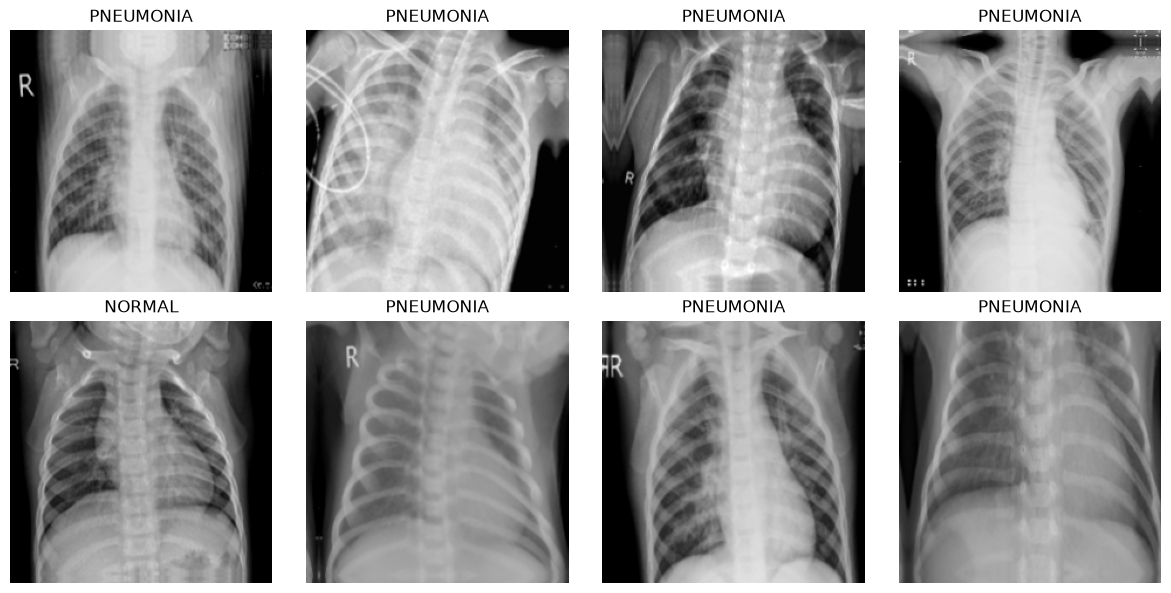

(32, 224, 224, 3)


In [7]:
images, labels = next(iter(train_ds))
plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title("PNEUMONIA" if labels[i] == 1 else "NORMAL")
    plt.axis("off")
plt.tight_layout()
plt.show()
print(images.shape)